<a href="https://colab.research.google.com/github/Team-JAZL/Fruitects-IS-DPC/blob/feat%2Fintelligent-systems-model-preparation/benchmarking/guava_type_classifier_model_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d amdatas/fruits-diseases-classification-dataset
!unzip -q fruits-diseases-classification-dataset.zip -d raw_dataset
print("Dataset downloaded and extracted successfully!")

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/amdatas/fruits-diseases-classification-dataset
License(s): MIT
fruits-diseases-classification-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace raw_dataset/FRUITS DISEASES CLASSIFICATION/APPLE/Blotch_Apple/_0_106.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
Dataset downloaded and extracted successfully!


In [2]:
import os
import shutil

source_dir = 'raw_dataset/FRUITS DISEASES CLASSIFICATION'
base_dest_dir = 'organized_guava_dataset'

# Mapping keywords in the original folder names to your desired class names
target_classes = {
    'anthracnose': 'Anthracnose',
    'fruitfly': 'Fruitfly',
    'healthy': 'Healthy'
}

# Create the new directory structure
for class_name in set(target_classes.values()):
    os.makedirs(os.path.join(base_dest_dir, class_name), exist_ok=True)

# Walk through the original dataset
if os.path.exists(source_dir):
    for root, dirs, files in os.walk(source_dir):
        folder_name = os.path.basename(root).lower()

        # We ONLY care about Guava folders for this notebook
        if 'guava' in folder_name:
            for key, class_name in target_classes.items():
                if key in folder_name:
                    for file in files:
                        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                            file_path = os.path.join(root, file)

                            # Append folder name to avoid duplicate file names
                            unique_filename = f"{folder_name}_{file}"
                            dest_path = os.path.join(base_dest_dir, class_name, unique_filename)
                            shutil.copy2(file_path, dest_path)
                    break # Move to the next folder once matched

    print("Guava data successfully reorganized into Anthracnose, Fruitfly, and Healthy classes.")
else:
    print(f"Directory {source_dir} not found. Please check the unzipped folder name.")

Guava data successfully reorganized into Anthracnose, Fruitfly, and Healthy classes.


In [3]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
SEED = 42

print("Loading Training Data...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dest_dir,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("\nLoading Validation/Test Data...")
val_test_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dest_dir,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names
print(f"\nClasses identified: {class_names}")

# Split the 30% validation pool evenly into Validation (15%) and Testing (15%)
val_batches = tf.data.experimental.cardinality(val_test_dataset)
val_dataset = val_test_dataset.take(val_batches // 2)
test_dataset = val_test_dataset.skip(val_batches // 2)

# Optimize performance
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Loading Training Data...
Found 300 files belonging to 3 classes.
Using 210 files for training.

Loading Validation/Test Data...
Found 300 files belonging to 3 classes.
Using 90 files for validation.

Classes identified: ['Anthracnose', 'Fruitfly', 'Healthy']


In [4]:
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def build_model(base_model_type, num_classes):
    input_shape = IMG_SIZE + (3,)

    if base_model_type == 'resnet50':
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
        preprocess_input = tf.keras.applications.resnet50.preprocess_input
    elif base_model_type == 'mobilenetv2':
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
        preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
    else:
        raise ValueError("Invalid model type")

    base_model.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)

    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

resnet_model = build_model('resnet50', len(class_names))
mobilenet_model = build_model('mobilenetv2', len(class_names))

--- Training ResNet-50 ---
Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.6238 - loss: 0.8495 - val_accuracy: 0.7812 - val_loss: 0.3972
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.9095 - loss: 0.2901 - val_accuracy: 0.9688 - val_loss: 0.1325
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.9905 - loss: 0.1147 - val_accuracy: 1.0000 - val_loss: 0.0886
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.9952 - loss: 0.0810 - val_accuracy: 1.0000 - val_loss: 0.0559
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 1.0000 - loss: 0.0533 - val_accuracy: 1.0000 - val_loss: 0.0406
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 1.0000 - loss: 0.0455 - val_accuracy: 1.0000 - val_loss: 0.0355
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 1.0000 - loss: 0.0337 - val_accuracy: 1.0000 - val_loss: 0.0290
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 1.0000 - loss: 0.0261 - val_accuracy: 

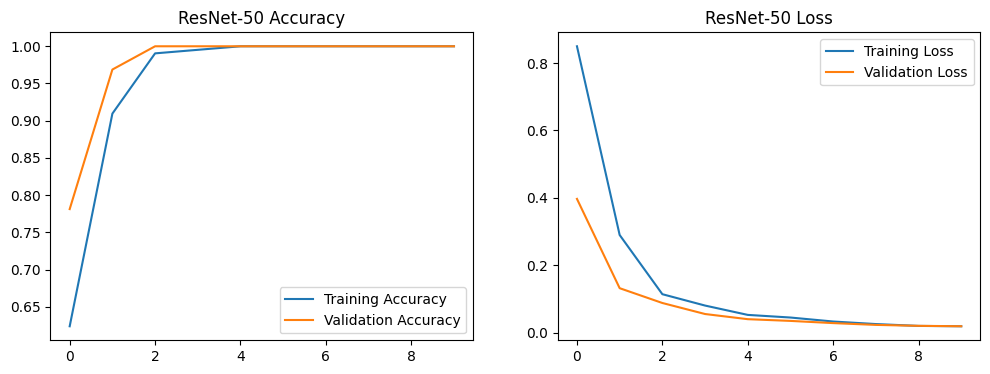

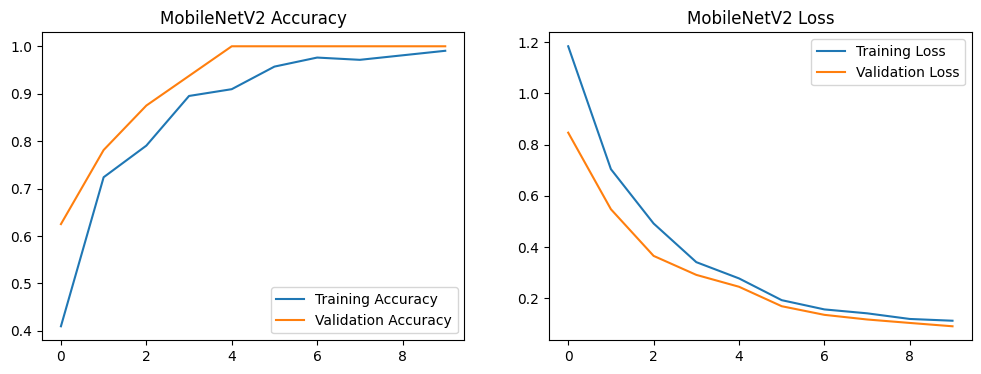

In [5]:
import matplotlib.pyplot as plt

EPOCHS = 10

print("--- Training ResNet-50 ---")
resnet_history = resnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

print("\n--- Training MobileNetV2 ---")
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(EPOCHS)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'{model_name} Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'{model_name} Loss')
    plt.show()

plot_history(resnet_history, 'ResNet-50')
plot_history(mobilenet_history, 'MobileNetV2')


Evaluating ResNet-50...

--- ResNet-50 Benchmark Results ---
Test Accuracy: 1.0000
Test Loss: 0.0215
Average Inference Latency per image: 188.75 ms

Classification Report:
              precision    recall  f1-score   support

 Anthracnose       1.00      1.00      1.00        20
    Fruitfly       1.00      1.00      1.00        22
     Healthy       1.00      1.00      1.00        16

    accuracy                           1.00        58
   macro avg       1.00      1.00      1.00        58
weighted avg       1.00      1.00      1.00        58



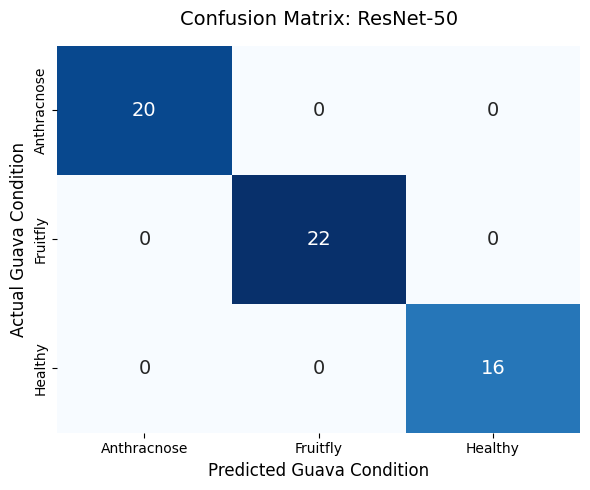


Evaluating MobileNetV2...

--- MobileNetV2 Benchmark Results ---
Test Accuracy: 1.0000
Test Loss: 0.1179
Average Inference Latency per image: 324.36 ms

Classification Report:
              precision    recall  f1-score   support

 Anthracnose       1.00      1.00      1.00        20
    Fruitfly       1.00      1.00      1.00        22
     Healthy       1.00      1.00      1.00        16

    accuracy                           1.00        58
   macro avg       1.00      1.00      1.00        58
weighted avg       1.00      1.00      1.00        58



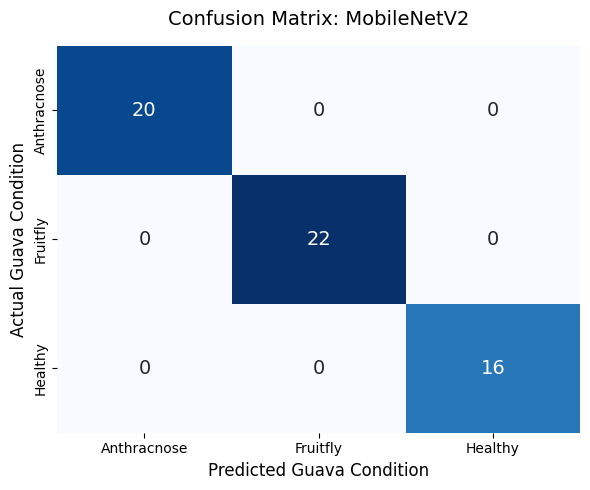

In [6]:
import time
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, dataset, model_name):
    print(f"\n{'='*40}")
    print(f"Evaluating {model_name}...")
    print(f"{'='*40}")

    y_true = []
    y_pred = []
    latencies = []

    for images, labels in dataset:
        y_true.extend(labels.numpy())

        start_time = time.time()
        preds = model.predict(images, verbose=0)
        end_time = time.time()

        batch_latency = (end_time - start_time) / len(images) * 1000
        latencies.append(batch_latency)
        y_pred.extend(np.argmax(preds, axis=1))

    loss, accuracy = model.evaluate(dataset, verbose=0)
    avg_latency = np.mean(latencies)

    print(f"\n--- {model_name} Benchmark Results ---")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Test Loss: {loss:.4f}")
    print(f"Average Inference Latency per image: {avg_latency:.2f} ms")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names,
                cbar=False,
                annot_kws={"size": 14})

    plt.title(f'Confusion Matrix: {model_name}', fontsize=14, pad=15)
    plt.ylabel('Actual Guava Condition', fontsize=12)
    plt.xlabel('Predicted Guava Condition', fontsize=12)
    plt.tight_layout()
    plt.show()

evaluate_model(resnet_model, test_dataset, "ResNet-50")
evaluate_model(mobilenet_model, test_dataset, "MobileNetV2")

In [7]:
import os

print("--- Selecting the Best Guava Disease Model ---")

resnet_loss, resnet_acc = resnet_model.evaluate(test_dataset, verbose=0)
mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(test_dataset, verbose=0)

if mobilenet_acc > resnet_acc:
    print("\n🏆 MobileNetV2 is the better model based on accuracy.")
    best_model = mobilenet_model
    best_model_name = "guava_type_classifier_mobilenetv2.keras"
elif resnet_acc > mobilenet_acc:
    print("\n🏆 ResNet-50 is the better model based on accuracy.")
    best_model = resnet_model
    best_model_name = "guava_type_classifier_resnet50.keras"
else:
    if mobilenet_loss < resnet_loss:
        print("\n🏆 Models tied on accuracy. MobileNetV2 selected based on lower loss.")
        best_model = mobilenet_model
        best_model_name = "guava_type_classifier_mobilenetv2.keras"
    else:
        print("\n🏆 Models tied on accuracy. ResNet-50 selected based on lower loss.")
        best_model = resnet_model
        best_model_name = "guava_type_classifier_resnet50.keras"

best_model.save(best_model_name)
print(f"\nModel successfully saved as: '{best_model_name}'")

file_size_mb = os.path.getsize(best_model_name) / (1024 * 1024)
print(f"Saved model file size: {file_size_mb:.2f} MB")

--- Selecting the Best Guava Disease Model ---

🏆 Models tied on accuracy. ResNet-50 selected based on lower loss.

Model successfully saved as: 'guava_type_classifier_resnet50.keras'
Saved model file size: 90.68 MB
